In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy.stats import ttest_ind
import scipy.stats as stats
from sqlalchemy import create_engine
from dotenv import load_dotenv
from sqlalchemy.engine import URL
import os

warnings.filterwarnings('ignore')

In [ ]:
load_dotenv()

engine = create_engine(
    URL.create(
        "postgresql+psycopg2",
        username=os.getenv("DB_USER"),
        password=os.getenv("DB_PASSWORD"),
        host=os.getenv("DB_HOST"),
        port=5432,
        database=os.getenv("DB_NAME")
    )
)

df = pd.read_sql(
    "SELECT * FROM vendor_sales_summary",
    engine
)

df.head()

,VendorNumber,VendorName,Brand,Description,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio
0,9552,M S WALKER INC,10937,Grahams 30-Yr Tawny Port,61.64,89.99,750.0,15.0,924.60,62.0,5579.38,3689.59,6.86,55551.82,4654.78,83.428266,4.133333,6.034372
1,6785,PALM BAY INTERNATIONAL INC,18433,Bertani Amarone 04,62.91,94.99,750.0,7.0,440.37,289.0,27452.11,21372.75,31.79,13605.41,27011.74,98.395861,41.285714,62.338738
2,9552,M S WALKER INC,36571,Matanzas Creek Chard Sonoma,16.33,25.99,750.0,12.0,195.96,93.0,2412.07,1445.44,10.37,55551.82,2216.11,91.875858,7.750000,12.308992
3,90017,THE IMPORTED GRAPE LLC,45577,Pacifico Sur Chard Curico,2.80,5.29,750.0,72.0,201.60,300.0,2187.00,364.50,33.70,80.03,1985.40,90.781893,4.166667,10.848214
4,2000,SOUTHERN WINE & SPIRITS NE,32137,F Coppola Diamond Znfd,9.39,15.99,750.0,1334.0,12526.26,6208.0,93857.92,67756.29,686.07,19016.59,81331.66,86.654019,4.653673,7.492893


In [6]:
df.describe()

,VendorNumber,Brand,PurchasePrice,ActualPrice,Volume,TotalPurchaseQuantity,TotalPurchaseDollars,TotalSalesQuantity,TotalSalesDollars,TotalSalesPrice,TotalExciseTax,FreightCost,GrossProfit,ProfitMargin,StockTurnover,SalesToPurchaseRatio
count,10692.000000,10692.000000,10692.000000,10692.000000,10692.000000,10692.000000,1.069200e+04,1.069200e+04,1.069200e+04,1.069200e+04,1.069200e+04,10692.000000,1.069200e+04,1.069200e+04,10692.000000,10692.000000
mean,10650.649458,18039.228769,24.385303,35.643671,847.360550,3140.886831,3.010669e+04,1.325377e+04,1.815934e+05,8.125527e+04,7.639402e+03,61433.763214,1.514867e+05,-inf,7.627864,11.186630
std,18753.519148,12662.187074,109.269375,148.246016,664.309212,11095.086769,1.230678e+05,4.728784e+04,7.195441e+05,1.952306e+05,4.723511e+04,60938.458032,5.970566e+05,NaN,28.046845,39.315037
min,2.000000,58.000000,0.360000,0.490000,50.000000,1.000000,7.100000e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.090000,-2.861408e+04,-inf,0.000000,0.000000
25%,3951.000000,5793.500000,6.840000,10.990000,750.000000,36.000000,4.534575e+02,1.440000e+02,3.131512e+03,1.259423e+03,2.090000e+01,14069.870000,2.329423e+03,7.940893e+01,3.390257,4.856475
50%,7153.000000,18761.500000,10.455000,15.990000,750.000000,262.000000,3.655465e+03,1.121000e+03,2.269242e+04,1.227813e+04,2.003900e+02,50293.620000,1.860121e+04,8.363188e+01,4.155225,6.109436
75%,9552.000000,25514.250000,19.482500,28.990000,750.000000,1975.750000,2.073824e+04,8.278250e+03,1.221461e+05,6.912702e+04,1.806815e+03,79528.990000,1.016019e+05,8.629269e+01,4.625649,7.295379
max,201359.000000,90631.000000,5681.810000,7499.990000,20000.000000,337660.000000,3.811252e+06,1.458251e+06,2.186914e+07,2.943279e+06,1.620550e+06,257032.070000,1.805789e+07,9.994180e+01,1336.300000,1718.100000


In [3]:

numerical_cols = df.select_dtypes(include='number').columns

print(numerical_cols)

Index(['VendorNumber', 'Brand', 'PurchasePrice', 'ActualPrice', 'Volume',
       'TotalPurchaseQuantity', 'TotalPurchaseDollars', 'TotalSalesQuantity',
       'TotalSalesDollars', 'TotalSalesPrice', 'TotalExciseTax', 'FreightCost',
       'GrossProfit', 'ProfitMargin', 'StockTurnover', 'SalesToPurchaseRatio'],
      dtype='str')


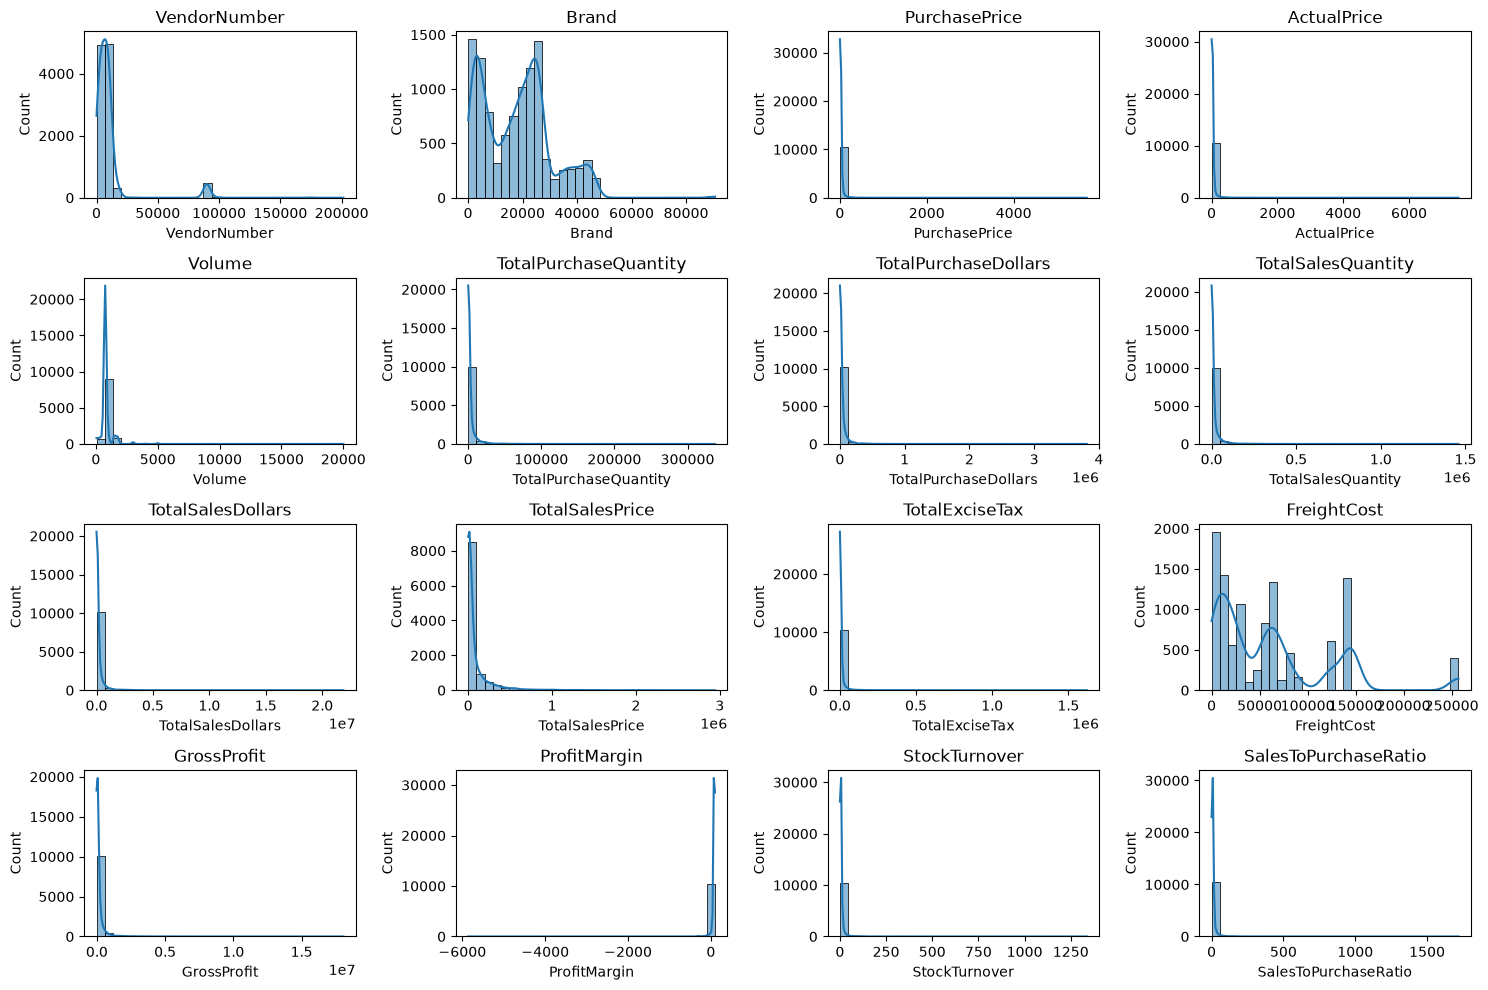

In [9]:
# Distribution Plots for Numerical Columns
# Histograms help us understand the distribution and spread of numerical variables.

numerical_cols = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(col)

plt.tight_layout()
plt.show()

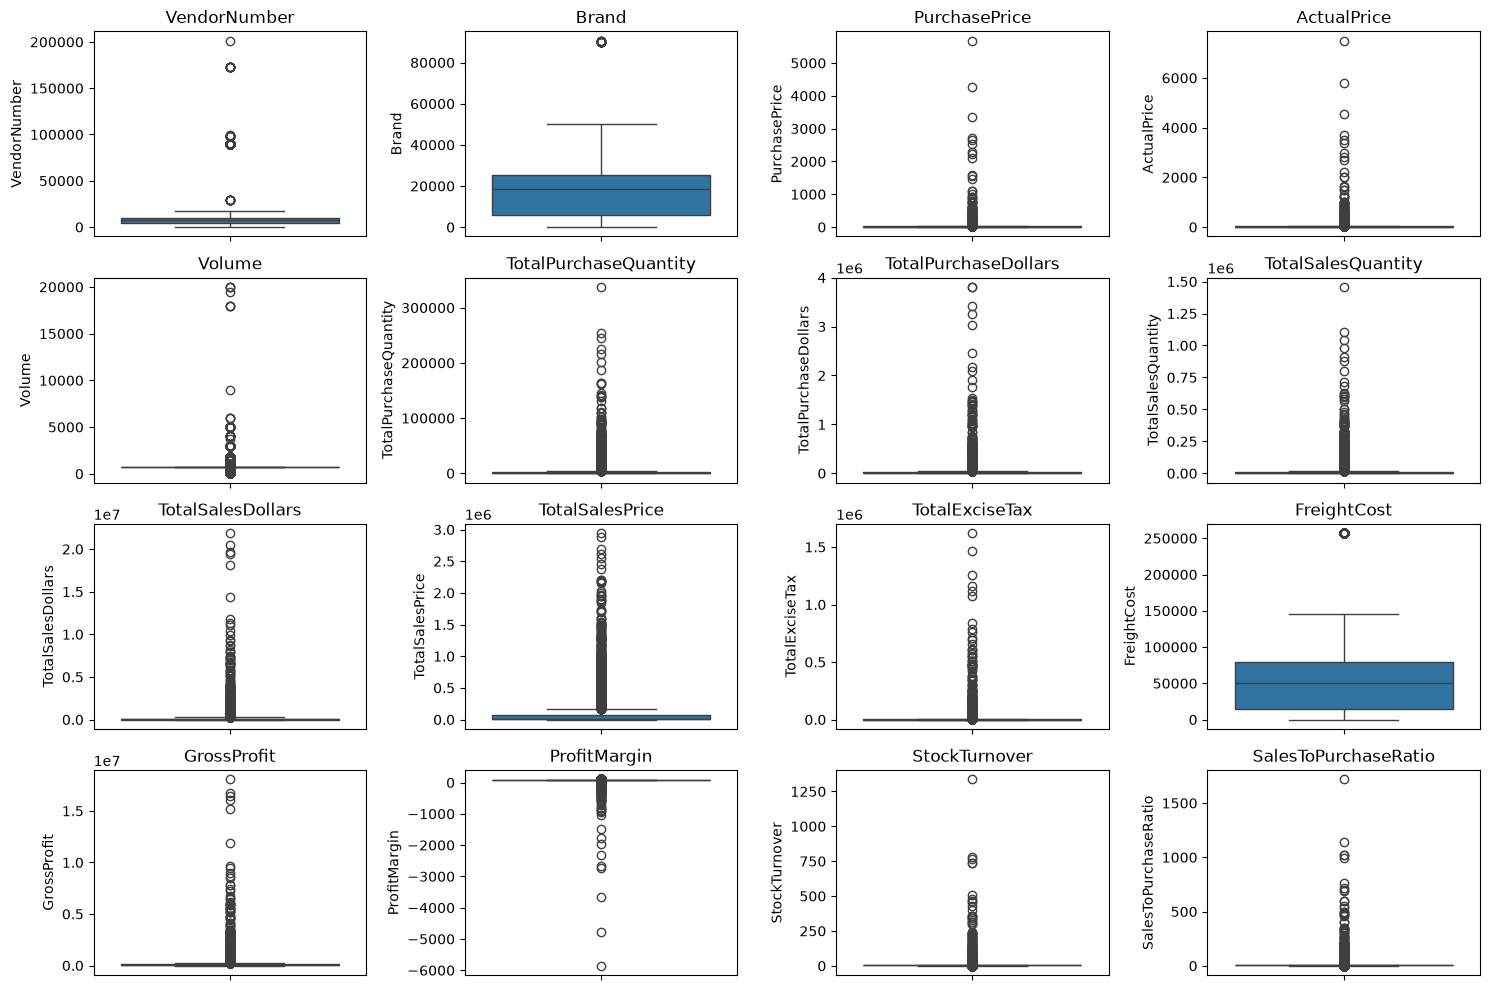

In [10]:
# Boxplots for Numerical Columns
# Boxplots help us identify outliers and understand the spread of numerical variables.

plt.figure(figsize=(15, 10))

for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

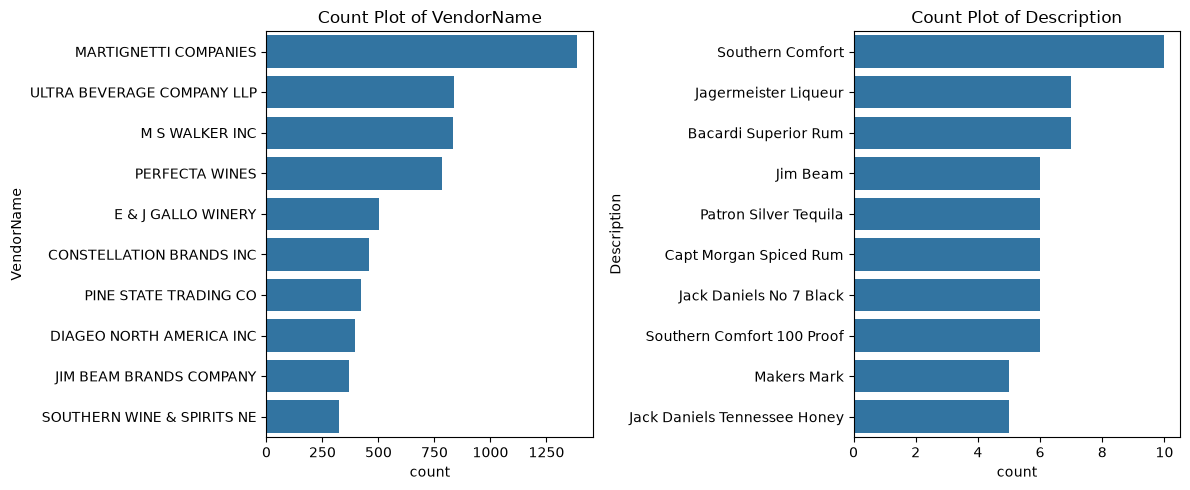

In [15]:
# Count Plots for Categorical Columns

categorical_cols = ["VendorName", "Description"]

plt.figure(figsize=(12, 5))

for i, col in enumerate(categorical_cols):
    plt.subplot(1, 2, i + 1)
    sns.countplot(
        y=df[col],
        order=df[col].value_counts().index[:10]
    )  # Top 10 categories
    plt.title(f"Count Plot of {col}")

plt.tight_layout()
plt.show()

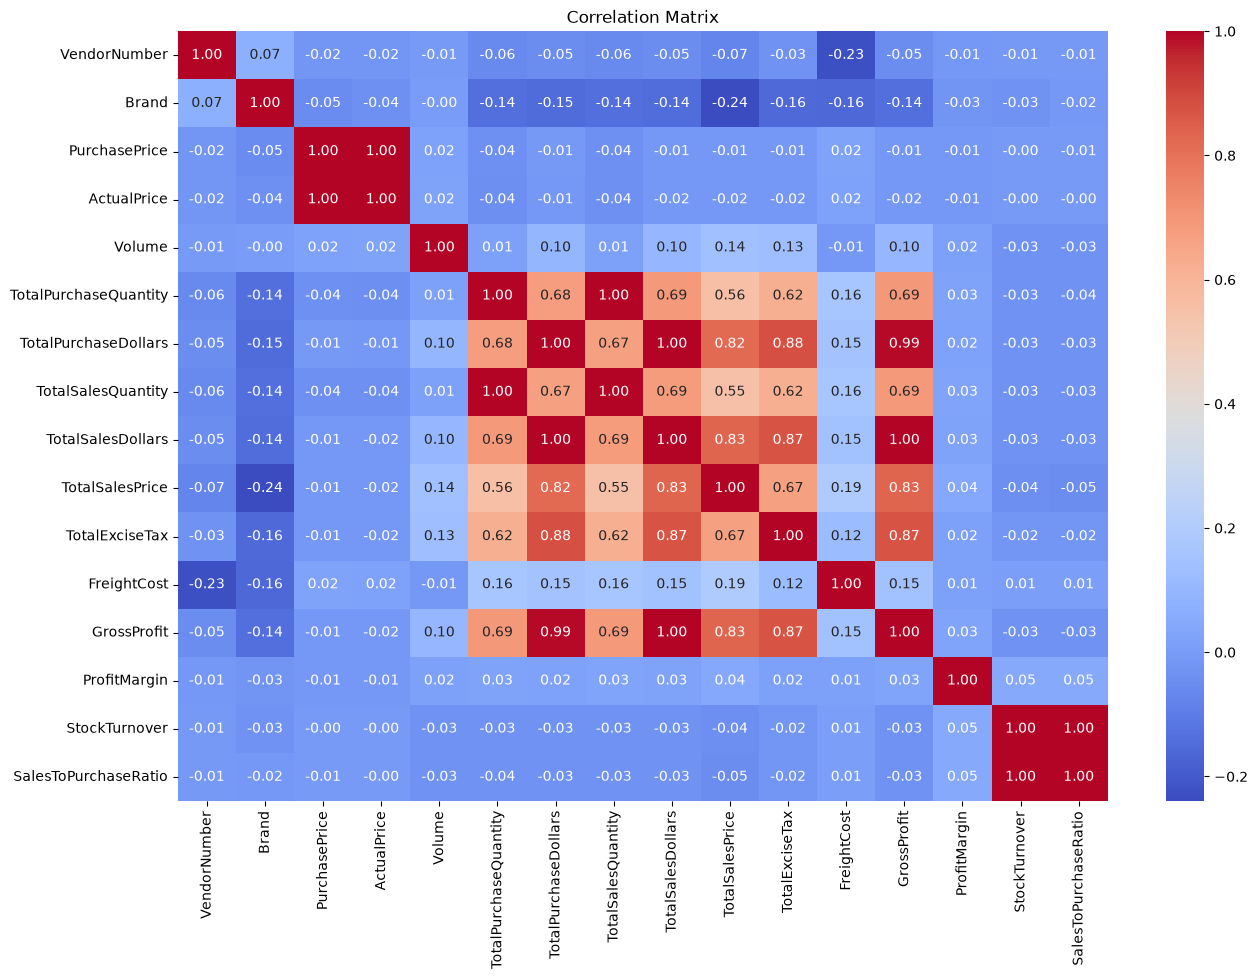

In [12]:
# Correlation Matrix
# Shows the relationship between numerical variables.

correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(15, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

In [16]:
# Identify products/brands with lower sales performance but higher profit margins

brand_performance = df.groupby('Description').agg({
    'TotalSalesDollars': 'sum',   # Total sales for each product/brand
    'ProfitMargin': 'mean'        # Average profit margin for each product/brand
}).reset_index()

brand_performance

,Description,TotalSalesDollars,ProfitMargin
0,(RI) 1,94245.09,81.290696
1,.nparalleled Svgn Blanc,4378.52,82.494542
2,10 Span Cab Svgn CC,11826.71,81.924305
3,10 Span Chard CC,14545.58,83.494367
4,10 Span Pnt Gris Monterey Cy,8598.52,83.587873
...,...,...,...
9646,Zuccardi Q Malbec,6556.72,80.995376
9647,Zum Rsl,46877.91,84.406941
9648,Zwack Liqueur,911.52,79.163375
9649,g Sake,3344.63,58.523364


In [20]:
# Define thresholds to identify low-sales and high-profit-margin products

low_sales_threshold = brand_performance['TotalSalesDollars'].quantile(0.15)

high_margin_threshold = brand_performance['ProfitMargin'].quantile(0.85)

low_sales_threshold


np.float64(1199.76)

In [ ]:
high_margin_threshold

np.float64(90.05364418488207)

In [21]:
# Filter products/brands with low sales but high profit margins

target_brands = brand_performance[
    (brand_performance['TotalSalesDollars'] <= low_sales_threshold) &
    (brand_performance['ProfitMargin'] >= high_margin_threshold)
]

print("Brands with Low Sales but High Profit Margins:")

display(target_brands.sort_values('TotalSalesDollars'))

Brands with Low Sales but High Profit Margins:


,Description,TotalSalesDollars,ProfitMargin
7777,Santa Rita Organic Svgn Bl,49.95,93.293293
2896,Debauchery Pnt Nr,57.90,93.195164
2537,Concannon Glen Ellen Wh Zin,79.75,96.689655
7818,Sauza Sprklg Wild Berry Marg,132.81,96.242753
2677,Crown Royal Apple,135.32,97.901271
...,...,...,...
7643,Ruca Malen Yauquen Bonarda,1158.55,93.862155
2857,DeKuyper Mixed Berry Medley,1175.93,99.323089
1165,Bowmore Legend Single Malt,1187.56,90.109131
9621,Zhenka Vodka 80 Proof,1193.97,97.443822


In [24]:
brand_performance = brand_performance[brand_performance['TotalSalesDollars']<10000] #for better visualization

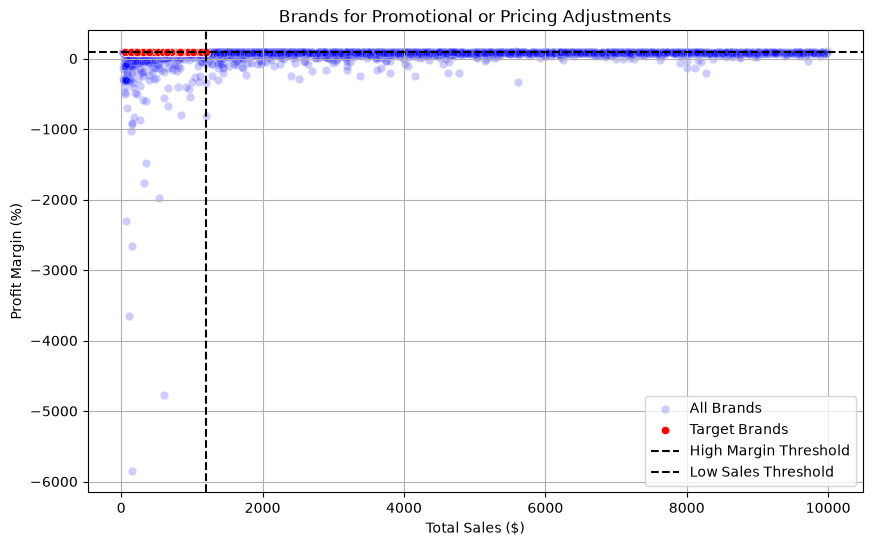

In [25]:
# Visualize products with low sales and high profit margins

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=brand_performance,
    x='TotalSalesDollars',
    y='ProfitMargin',
    color='blue',
    label='All Brands',
    alpha=0.2
)

sns.scatterplot(
    data=target_brands,
    x='TotalSalesDollars',
    y='ProfitMargin',
    color='red',
    label='Target Brands'
)

# Show the high profit margin threshold
plt.axhline(
    high_margin_threshold,
    linestyle='--',
    color='black',
    label='High Margin Threshold'
)

# Show the low sales threshold
plt.axvline(
    low_sales_threshold,
    linestyle='--',
    color='black',
    label='Low Sales Threshold'
)

plt.xlabel("Total Sales ($)")
plt.ylabel("Profit Margin (%)")
plt.title("Brands for Promotional or Pricing Adjustments")
plt.legend()
plt.grid(True)
plt.show()

In [2]:
# Format large dollar values for better readability

def format_dollars(value):
    if value >= 1_000_000:
        return f"${value / 1_000_000:.2f}M"
    elif value >= 1_000:
        return f"${value / 1_000:.2f}K"
    else:
        return str(value)

In [5]:
# Identify the Top 10 Vendors and Top 10 Brands based on total sales

top_vendors = df.groupby("VendorName")["TotalSalesDollars"].sum().nlargest(10)

top_brands = df.groupby("Description")["TotalSalesDollars"].sum().nlargest(10)

top_vendors

VendorName
DIAGEO NORTH AMERICA INC      2.952578e+08
MARTIGNETTI COMPANIES         1.754068e+08
PERNOD RICARD USA             1.386762e+08
JIM BEAM BRANDS COMPANY       1.379346e+08
BACARDI USA INC               1.068702e+08
CONSTELLATION BRANDS INC      1.053616e+08
E & J GALLO WINERY            8.007981e+07
BROWN-FORMAN CORP             7.959282e+07
ULTRA BEVERAGE COMPANY LLP    7.662234e+07
M S WALKER INC                6.660719e+07
Name: TotalSalesDollars, dtype: float64

In [6]:
top_brands

Description
Jack Daniels No 7 Black    3.423139e+07
Tito's Handmade Vodka      3.150172e+07
Grey Goose Vodka           3.052480e+07
Capt Morgan Spiced Rum     2.782244e+07
Absolut 80 Proof           2.679092e+07
Jameson Irish Whiskey      2.453969e+07
Ketel One Vodka            2.181788e+07
Baileys Irish Cream        1.778367e+07
Kahlua                     1.556633e+07
Tanqueray                  1.482796e+07
Name: TotalSalesDollars, dtype: float64

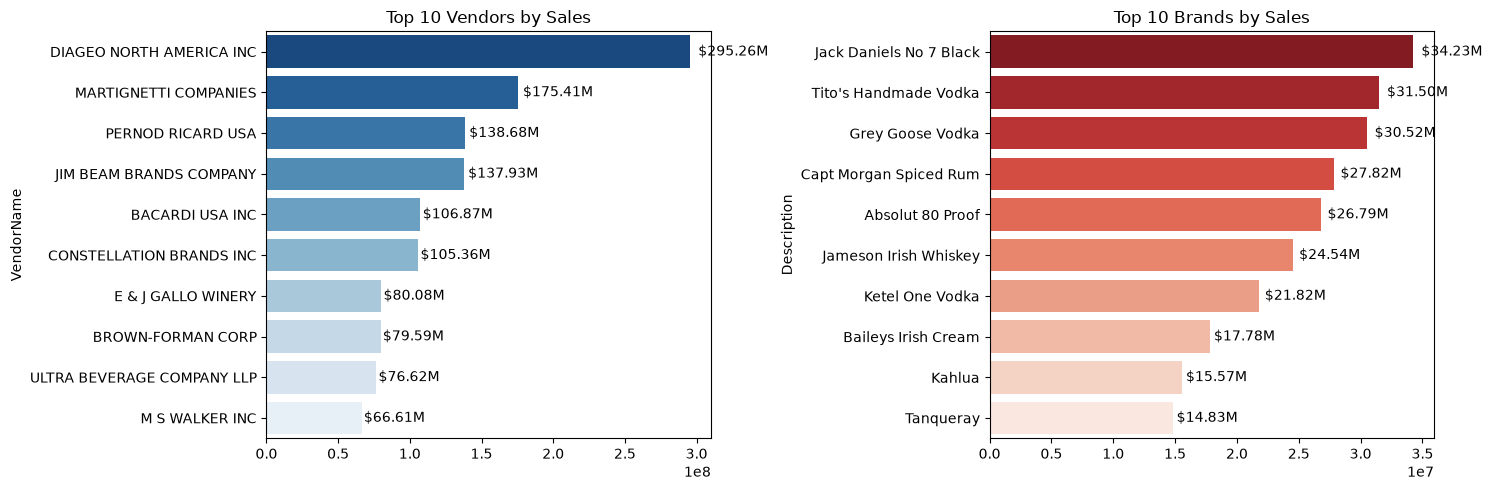

In [7]:
# Visualize Top 10 Vendors and Top 10 Brands by Sales

plt.figure(figsize=(15, 5))

# Plot for Top Vendors
plt.subplot(1, 2, 1)

ax1 = sns.barplot(
    y=top_vendors.index,
    x=top_vendors.values,
    palette="Blues_r"
)

plt.title("Top 10 Vendors by Sales")

for bar in ax1.patches:
    ax1.text(
        bar.get_width() + (bar.get_width() * 0.02),
        bar.get_y() + bar.get_height() / 2,
        format_dollars(bar.get_width()),
        ha='left',
        va='center',
        fontsize=10,
        color='black'
    )

# Plot for Top Brands
plt.subplot(1, 2, 2)

ax2 = sns.barplot(
    y=top_brands.index.astype(str),
    x=top_brands.values,
    palette="Reds_r"
)

plt.title("Top 10 Brands by Sales")

for bar in ax2.patches:
    ax2.text(
        bar.get_width() + (bar.get_width() * 0.02),
        bar.get_y() + bar.get_height() / 2,
        format_dollars(bar.get_width()),
        ha='left',
        va='center',
        fontsize=10,
        color='black'
    )

plt.tight_layout()
plt.show()

In [6]:
#which vendor contributes the most  to total purchase dollars?
# Vendor-wise performance analysis

vendor_performance = df.groupby('VendorName').agg({
    'TotalPurchaseDollars': 'sum',
    'GrossProfit': 'sum',
    'TotalSalesDollars': 'sum'
}).reset_index()

vendor_performance.shape

(128, 4)

In [ ]:
#Purchase Contribution %
vendor_performance['Purchase_Contribution%'] = (
    vendor_performance['TotalPurchaseDollars']
    / vendor_performance['TotalPurchaseDollars'].sum()
) * 100

#Sort Vendors
vendor_performance = round(
    vendor_performance.sort_values(
        'Purchase_Contribution%',
        ascending=False
    ), 2
)
#Display Top 10 Vendors
top_vendors = vendor_performance.head(10).copy()
top_vendors

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,Purchase_Contribution%
28,DIAGEO NORTH AMERICA INC,50959796.85,2.442980e+08,2.952578e+08,15.83
63,MARTIGNETTI COMPANIES,27861690.02,1.475451e+08,1.754068e+08,8.66
50,JIM BEAM BRANDS COMPANY,24203151.05,1.137314e+08,1.379346e+08,7.52
74,PERNOD RICARD USA,24124091.56,1.145521e+08,1.386762e+08,7.49
8,BACARDI USA INC,17624378.72,8.924580e+07,1.068702e+08,5.48
23,CONSTELLATION BRANDS INC,15573917.90,8.978768e+07,1.053616e+08,4.84
14,BROWN-FORMAN CORP,13529433.08,6.606339e+07,7.959282e+07,4.20
114,ULTRA BEVERAGE COMPANY LLP,13210613.93,6.341172e+07,7.662234e+07,4.10
33,E & J GALLO WINERY,12289608.09,6.779020e+07,8.007981e+07,3.82
59,M S WALKER INC,10935817.30,5.567137e+07,6.660719e+07,3.40


In [8]:
#Again Data formatting
top_vendors['TotalSalesDollars'] = (
    top_vendors['TotalSalesDollars'].apply(format_dollars)
)

top_vendors['TotalPurchaseDollars'] = (
    top_vendors['TotalPurchaseDollars'].apply(format_dollars)
)

top_vendors['GrossProfit'] = (
    top_vendors['GrossProfit'].apply(format_dollars)
)

top_vendors

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,Purchase_Contribution%
28,DIAGEO NORTH AMERICA INC,$50.96M,$244.30M,$295.26M,15.83
63,MARTIGNETTI COMPANIES,$27.86M,$147.55M,$175.41M,8.66
50,JIM BEAM BRANDS COMPANY,$24.20M,$113.73M,$137.93M,7.52
74,PERNOD RICARD USA,$24.12M,$114.55M,$138.68M,7.49
8,BACARDI USA INC,$17.62M,$89.25M,$106.87M,5.48
23,CONSTELLATION BRANDS INC,$15.57M,$89.79M,$105.36M,4.84
14,BROWN-FORMAN CORP,$13.53M,$66.06M,$79.59M,4.20
114,ULTRA BEVERAGE COMPANY LLP,$13.21M,$63.41M,$76.62M,4.10
33,E & J GALLO WINERY,$12.29M,$67.79M,$80.08M,3.82
59,M S WALKER INC,$10.94M,$55.67M,$66.61M,3.40


In [9]:
top_vendors['Purchase_Contribution%'].sum()

np.float64(65.34)

In [10]:
top_vendors['Cumulative_Contribution%'] = (
    top_vendors['Purchase_Contribution%'].cumsum()
)

top_vendors

,VendorName,TotalPurchaseDollars,GrossProfit,TotalSalesDollars,Purchase_Contribution%,Cumulative_Contribution%
28,DIAGEO NORTH AMERICA INC,$50.96M,$244.30M,$295.26M,15.83,15.83
63,MARTIGNETTI COMPANIES,$27.86M,$147.55M,$175.41M,8.66,24.49
50,JIM BEAM BRANDS COMPANY,$24.20M,$113.73M,$137.93M,7.52,32.01
74,PERNOD RICARD USA,$24.12M,$114.55M,$138.68M,7.49,39.50
8,BACARDI USA INC,$17.62M,$89.25M,$106.87M,5.48,44.98
23,CONSTELLATION BRANDS INC,$15.57M,$89.79M,$105.36M,4.84,49.82
14,BROWN-FORMAN CORP,$13.53M,$66.06M,$79.59M,4.20,54.02
114,ULTRA BEVERAGE COMPANY LLP,$13.21M,$63.41M,$76.62M,4.10,58.12
33,E & J GALLO WINERY,$12.29M,$67.79M,$80.08M,3.82,61.94
59,M S WALKER INC,$10.94M,$55.67M,$66.61M,3.40,65.34


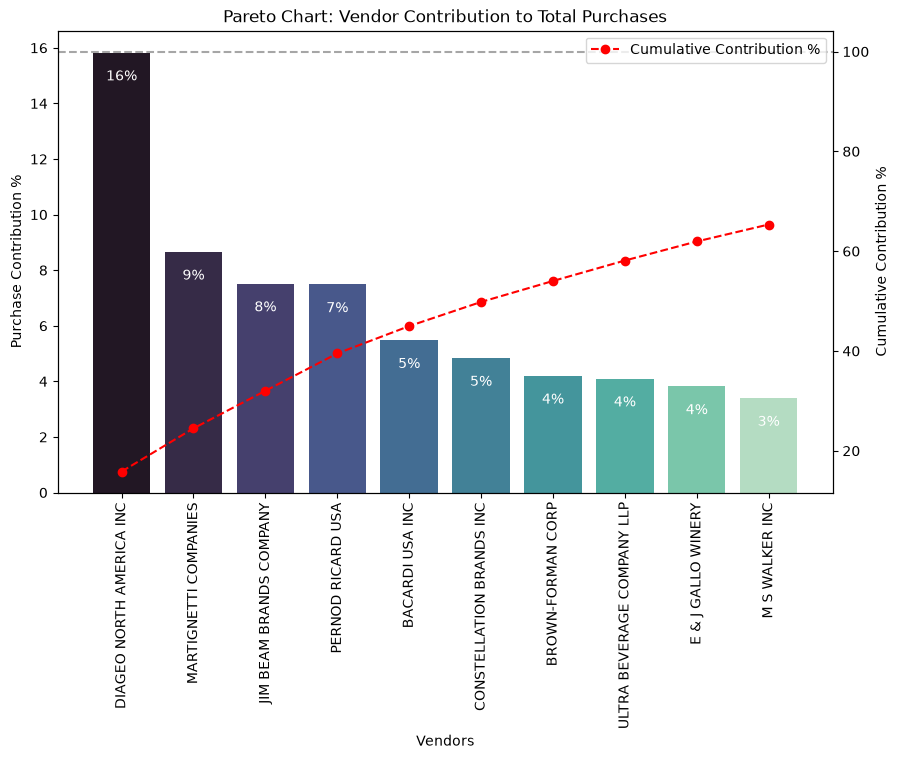

In [11]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar plot for Purchase Contribution%
sns.barplot(
    x=top_vendors['VendorName'],
    y=top_vendors['Purchase_Contribution%'],
    palette='mako',
    ax=ax1
)

for i, value in enumerate(top_vendors['Purchase_Contribution%']):
    ax1.text(
        i,
        value - 1,
        str(round(value)) + '%',
        ha='center',
        fontsize=10,
        color='white'
    )

# Line plot for Cumulative Contribution%
ax2 = ax1.twinx()

ax2.plot(
    top_vendors['VendorName'],
    top_vendors['Cumulative_Contribution%'],
    color='red',
    marker='o',
    linestyle='dashed',
    label='Cumulative Contribution %'
)

ax1.set_xticklabels(
    top_vendors['VendorName'],
    rotation=90
)

ax1.set_ylabel('Purchase Contribution %')
ax2.set_ylabel('Cumulative Contribution %')
ax1.set_xlabel('Vendors')

ax1.set_title(
    'Pareto Chart: Vendor Contribution to Total Purchases'
)

ax2.axhline(
    y=100,
    color='gray',
    linestyle='dashed',
    alpha=0.7
)

ax2.legend(loc='upper right')

plt.show()

In [12]:
# Calculate total purchase contribution of top 10 vendors
print(
    f"Total Purchase Contribution of top 10 vendors is "
    f"{round(top_vendors['Purchase_Contribution%'].sum(), 2)} %"
)

Total Purchase Contribution of top 10 vendors is 65.34 %


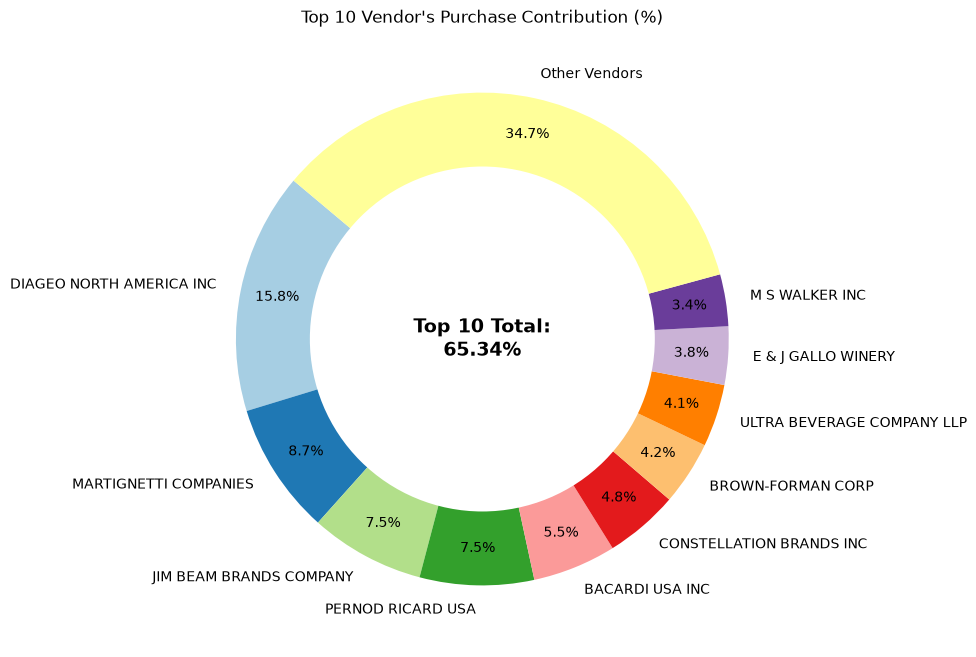

In [13]:
# Create list of vendor names
vendors = list(top_vendors['VendorName'].values)

# Create list of purchase contribution percentages
purchase_contributions = list(
    top_vendors['Purchase_Contribution%'].values
)

# Calculate total contribution of top 10 vendors
total_contribution = sum(purchase_contributions)

# Calculate contribution of all remaining vendors
remaining_contribution = 100 - total_contribution


# Append "Other Vendors" category
vendors.append("Other Vendors")
purchase_contributions.append(remaining_contribution)


# Donut Chart
fig, ax = plt.subplots(figsize=(8, 8))

wedges, texts, autotexts = ax.pie(
    purchase_contributions,
    labels=vendors,
    autopct='%1.1f%%',
    startangle=140,
    pctdistance=0.85,
    colors=plt.cm.Paired.colors
)


# Draw a white circle in the center
centre_circle = plt.Circle(
    (0, 0),
    0.70,
    fc='white'
)

fig.gca().add_artist(centre_circle)


# Add total contribution annotation in the center
plt.text(
    0,
    0,
    f"Top 10 Total:\n{total_contribution:.2f}%",
    fontsize=14,
    fontweight='bold',
    ha='center',
    va='center'
)


# Add chart title
plt.title("Top 10 Vendor's Purchase Contribution (%)")

plt.show()

In [14]:
#Does purchasing in bulk reduce the unit price, and what is the optimal purchase volume for cost savings?
# Calculate Unit Purchase Price
df['UnitPurchasePrice'] = (
    df['TotalPurchaseDollars'] /
    df['TotalPurchaseQuantity']
)

In [15]:
# Create Order Size categories based on purchase quantity
df['OrderSize'] = pd.qcut(
    df['TotalPurchaseQuantity'],
    q=3,
    labels=['Small', 'Medium', 'Large']
)

In [16]:
# Calculate average unit purchase price for each order size
df.groupby('OrderSize')[['UnitPurchasePrice']].mean()

,UnitPurchasePrice
OrderSize,
Small,43.776954
Medium,17.894005
Large,11.308807


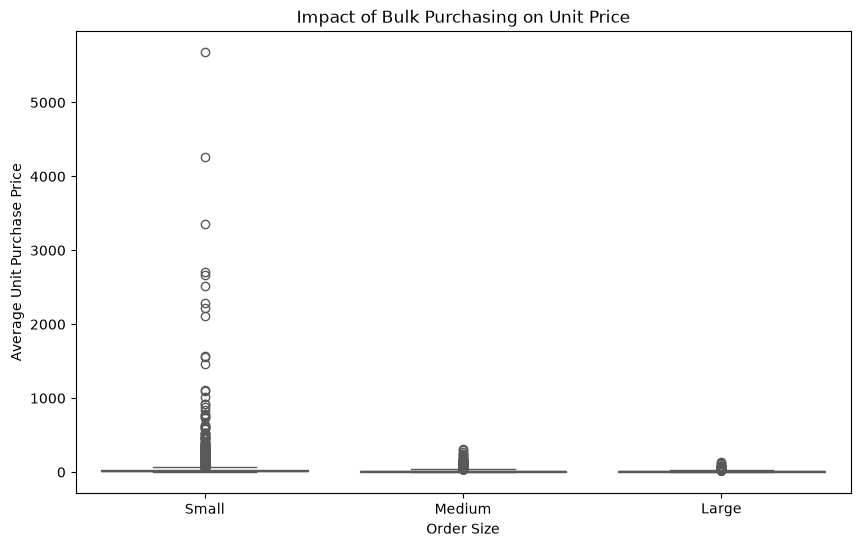

In [17]:
# Create boxplot to compare unit purchase prices
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='OrderSize',
    y='UnitPurchasePrice',
    palette='Set2'
)

# Add chart title and labels
plt.title('Impact of Bulk Purchasing on Unit Price')
plt.xlabel('Order Size')
plt.ylabel('Average Unit Purchase Price')

plt.show()

In [18]:
# Filter vendors with low stock turnover
# Stock turnover less than 1 indicates slow-moving inventory
low_turnover_vendors = (
    df[df['StockTurnover'] < 1]
    .groupby('VendorName')[['StockTurnover']]
    .mean()
    .sort_values('StockTurnover', ascending=True)
    .head(10)
)

# Display top 10 vendors with the lowest stock turnover
low_turnover_vendors

,StockTurnover
VendorName,
AAPER ALCOHOL & CHEMICAL CO,0.000000
ADAMBA IMPORTS INTL INC,0.000000
BACARDI USA INC,0.000000
CAMPARI AMERICA,0.000000
LAUREATE IMPORTS CO,0.000000
MILTONS DISTRIBUTING CO,0.000000
SURVILLE ENTERPRISES CORP,0.000000
MHW LTD,0.061404
HIGHLAND WINE MERCHANTS LLC,0.063492


In [19]:
# Calculate the value of unsold inventory
# Unsold Quantity = Total Purchase Quantity - Total Sales Quantity
df['UnsoldInventoryValue'] = (
    (df['TotalPurchaseQuantity'] - df['TotalSalesQuantity'])
    * df['PurchasePrice']
)

# Calculate total capital locked in unsold inventory
print(
    'Total Unsold Capital:',
    format_dollars(df['UnsoldInventoryValue'].sum())
)

Total Unsold Capital: -1022608832.78


In [20]:
# Aggregate unsold inventory value per vendor
inventory_value_per_vendor = (
    df.groupby('VendorName')[['UnsoldInventoryValue']]
    .sum()
    .reset_index()
)

# Sort vendors by highest locked capital
inventory_value_per_vendor = (
    inventory_value_per_vendor
    .sort_values(
        by='UnsoldInventoryValue',
        ascending=False
    )
)

# Format the inventory value as dollars
inventory_value_per_vendor['UnsoldInventoryValue'] = (
    inventory_value_per_vendor['UnsoldInventoryValue']
    .apply(format_dollars)
)

# Display top 10 vendors with highest locked capital
inventory_value_per_vendor.head(10)

,VendorName,UnsoldInventoryValue
48,"IRA GOLDMAN AND WILLIAMS, LLP",$1.94K
45,HIGHLAND WINE MERCHANTS LLC,986.3799999999999
112,TRUETT HURST,197.2
56,LAUREATE IMPORTS CO,140.94
0,AAPER ALCOHOL & CHEMICAL CO,105.07
115,UNCORKED,-20.72999999999996
57,LOYAL DOG WINERY,-541.52
119,VINEYARD BRANDS LLC,-567.5699999999997
36,FANTASY FINE WINES CORP,-804.0
19,CAPSTONE INTERNATIONAL,-833.26


In [21]:
# Calculate the 75th percentile of total sales
# Vendors above this are considered top-performing
top_threshold = df['TotalSalesDollars'].quantile(0.75)

# Calculate the 25th percentile of total sales
# Vendors below this are considered low-performing
low_threshold = df['TotalSalesDollars'].quantile(0.25)

In [8]:
# Calculate the 75th percentile of total sales
# Vendors above this are considered top-performing
top_threshold = df['TotalSalesDollars'].quantile(0.75)

# Calculate the 25th percentile of total sales
# Vendors below this are considered low-performing
low_threshold = df['TotalSalesDollars'].quantile(0.25)

In [9]:
# Select profit margins of top-performing vendors
top_vendors = (
    df[df['TotalSalesDollars'] >= top_threshold]['ProfitMargin']
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

# Select profit margins of low-performing vendors
low_vendors = (
    df[df['TotalSalesDollars'] <= low_threshold]['ProfitMargin']
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

In [10]:
# Function to calculate confidence interval
def confidence_interval(data, confidence=0.95):

    # Calculate the mean
    mean_val = np.mean(data)

    # Calculate standard error
    std_err = np.std(data, ddof=1) / np.sqrt(len(data))

    # Calculate critical t-value
    t_critical = stats.t.ppf(
        (1 + confidence) / 2,
        df=len(data) - 1
    )

    # Calculate margin of error
    margin_of_error = t_critical * std_err

    # Return mean and confidence interval
    return (
        mean_val,
        mean_val - margin_of_error,
        mean_val + margin_of_error
    )

In [11]:
# Calculate 95% confidence interval for top vendors
top_mean, top_lower, top_upper = confidence_interval(top_vendors)

# Calculate 95% confidence interval for low vendors
low_mean, low_lower, low_upper = confidence_interval(low_vendors)

# Print confidence intervals
print(
    f"Top Vendors 95% CI: ({top_lower:.2f}, {top_upper:.2f}), "
    f"Mean: {top_mean:.2f}"
)

print(
    f"Low Vendors 95% CI: ({low_lower:.2f}, {low_upper:.2f}), "
    f"Mean: {low_mean:.2f}"
)

Top Vendors 95% CI: (83.58, 83.84), Mean: 83.71
Low Vendors 95% CI: (31.48, 49.01), Mean: 40.25


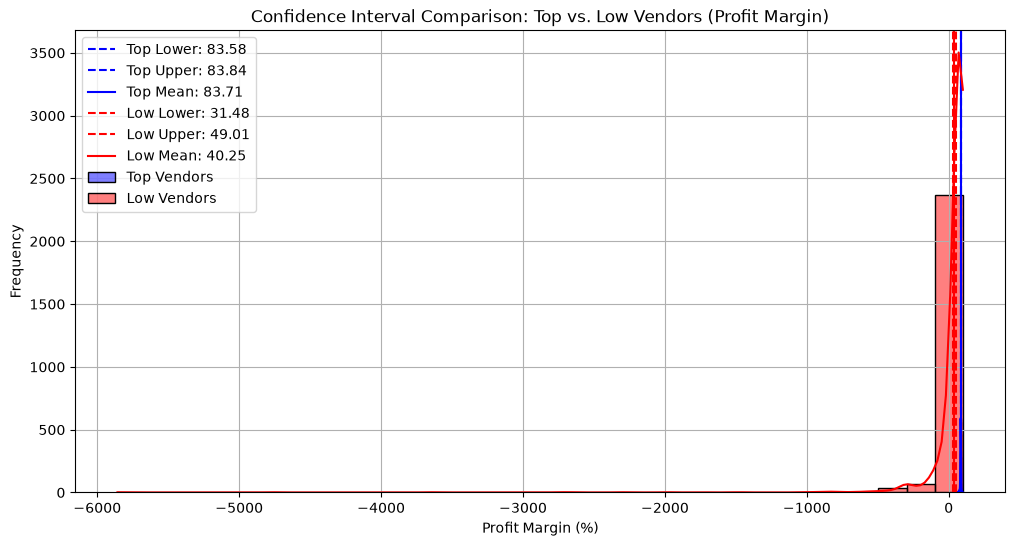

In [12]:
# Create figure
plt.figure(figsize=(12, 6))


# Top Vendors Plot
sns.histplot(
    top_vendors,
    kde=True,
    color='blue',
    bins=30,
    alpha=0.5,
    label='Top Vendors'
)

# Top vendors lower confidence limit
plt.axvline(
    top_lower,
    color='blue',
    linestyle='--',
    label=f'Top Lower: {top_lower:.2f}'
)

# Top vendors upper confidence limit
plt.axvline(
    top_upper,
    color='blue',
    linestyle='--',
    label=f'Top Upper: {top_upper:.2f}'
)

# Top vendors mean
plt.axvline(
    top_mean,
    color='blue',
    linestyle='-',
    label=f'Top Mean: {top_mean:.2f}'
)


# Low Vendors Plot
sns.histplot(
    low_vendors,
    kde=True,
    color='red',
    bins=30,
    alpha=0.5,
    label='Low Vendors'
)

# Low vendors lower confidence limit
plt.axvline(
    low_lower,
    color='red',
    linestyle='--',
    label=f'Low Lower: {low_lower:.2f}'
)

# Low vendors upper confidence limit
plt.axvline(
    low_upper,
    color='red',
    linestyle='--',
    label=f'Low Upper: {low_upper:.2f}'
)

# Low vendors mean
plt.axvline(
    low_mean,
    color='red',
    linestyle='-',
    label=f'Low Mean: {low_mean:.2f}'
)


# Finalize plot
plt.title(
    'Confidence Interval Comparison: Top vs. Low Vendors (Profit Margin)'
)

plt.xlabel('Profit Margin (%)')
plt.ylabel('Frequency')

plt.legend()
plt.grid(True)

plt.show()